# Imports

In [ ]:
import os
import pandas as pd
import numpy as np
from scipy.stats import norm, gaussian_kde
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# Setup

In [71]:
##############################
# Read Dataset into Dataframe
##############################

# path to cleaned dataset
clean_path = r'../data/mnz_cleaned.csv'


##### read into df...
df = pd.read_csv(clean_path)
df.sort_values('error', inplace=True)
df.reset_index(inplace=True)
df.head()

,index,sample,zone,mnz,texture,texture_chem,n,age,error,CaO,...,Tb2O3,Dy2O3,Ho2O3,Er2O3,Tm2O3,Yb2O3,SO3,PbO,lree,HREE
0,8,EB14-001,CMZI,m28,overgrowth,Y depleted overgrowth,6.0,348.85,0.701308,0.995224,...,0.023879,0.181849,0.021200,0.034744,0.069987,0.009827,0.019002,0.097798,60.335048,1.371961
1,111,P14-003-2B,MDHSZ,m50,core,Th enriched core,5.0,307.14,0.794103,1.435283,...,0.010042,0.010042,0.010042,0.010042,0.020180,0.010042,0.018376,0.134090,58.128568,0.677921
2,176,P14-005A-5B,CBSZ,m20,core,Y depleted core,NaN,356.00,0.800000,0.827626,...,0.016850,0.125878,0.009912,0.014868,0.009912,0.009912,0.020815,0.080285,62.602214,1.604702
3,114,M1605-2-L3,MDHSZ,m4,rim,Y depleted rim,5.0,298.70,1.381304,0.852869,...,0.012597,0.062720,0.009927,0.009927,0.009927,0.009927,0.016638,0.084487,62.652220,1.401806
4,31,WA14-002,CMZI,m22,rim,Y depleted rim,5.0,353.24,1.461027,0.984389,...,0.009819,0.079168,0.009819,0.009819,0.061324,0.009819,0.015049,0.087027,61.816443,1.415405


# Age Plots

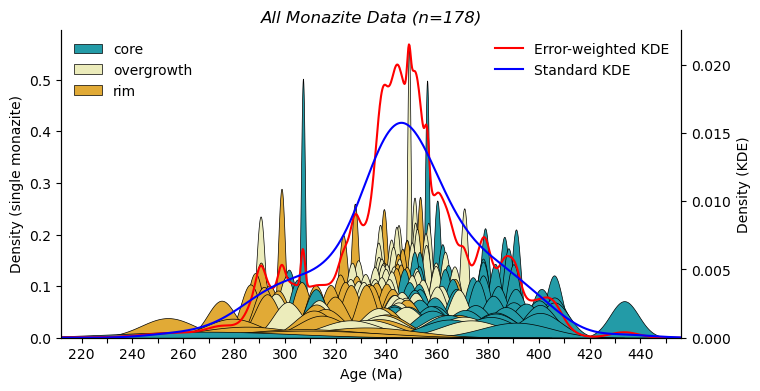

In [ ]:
###################################
# Distributions of Ages (All Data)
###################################

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8,4))


##### plot individual PDFs for each monazite analysis...
texture_colors = {'core': '#239BA7', 
                  'overgrowth': '#ECECBB', 
                  'rim': '#E1AA36'}

for idx, row in df.iterrows():
    mean = row['age']
    error = row['error']
    tex = row['texture']
    age_range = np.linspace(mean - 4 * error, mean + 4 * error, 100)
    density = norm.pdf(age_range, mean, error)
    ax.fill_between(age_range, density, alpha=1, color=texture_colors.get(tex), linewidth=0.5, edgecolor='k')

    if mean == df['age'].min():
        xmin = age_range.min()
    if mean == df['age'].max():
        xmax = age_range.max()


##### plot KDEs...
ages = df['age'].to_numpy()
errors = df['error'].to_numpy()
t = np.linspace(xmin, xmax, 1000)

# error-weighted KDE...
density_err = np.zeros_like(t)
for age, err in zip(ages, errors):
    density_err += np.exp(-(t-age)**2 / (2*err**2)) / (np.sqrt(2*np.pi)*err)
density_err /= len(ages)

# standard KDE...
kde = gaussian_kde(ages)
density_std = kde(t)

# plot KDEs...
ax2 = ax.twinx()
ax2.plot(t, density_err, color='red', label='Error-weighted KDE')
ax2.plot(t, density_std, color='blue', label='Standard KDE')


##### legend...
ax1_patches = []
for k,v in texture_colors.items():
    ax1_patches.append(Patch(facecolor=v, edgecolor='k', linewidth=0.5, label=k))
ax.legend(ax1_patches, [lab.get_label() for lab in ax1_patches], loc='upper left', bbox_to_anchor=(0,1), frameon=False)
ax2.legend(loc='upper right', bbox_to_anchor=(1,1), frameon=False)


##### figure styling...
ax.set_xlim(xmin, xmax)
ax.set_xticks(np.arange(220, 451, 10))
ax.set_xticklabels([str(i) if i%20 == 0 else '' for i in np.arange(220, 451, 10)])
ax.set_xlabel('Age (Ma)')
ax.set_ylim(0)
ax2.set_ylim(0)

ax.set_ylabel('Density (single monazite)')
ax2.set_ylabel('Density (KDE)')

ax.set_title(f"All Monazite Data (n={len(df)})", style='italic')
ax.spines['top'].set_visible(False)
ax2.spines['top'].set_visible(False)

# plt.savefig('all_ages.png', bbox_inches="tight", pad_inches=0, dpi=300)
plt.show()

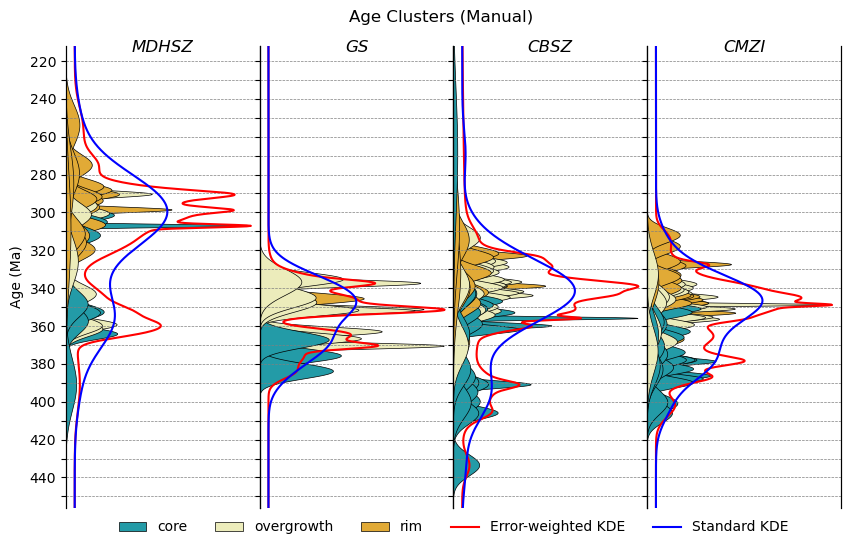

In [ ]:
##########################################
# Distributions of Ages by Structural Zone
##########################################

fig, ax = plt.subplots(nrows=1, ncols=4, sharey=True, figsize=(10,6))
plt.subplots_adjust(wspace=0)

structural_zones = ['MDHSZ', 'GS', 'CBSZ', 'CMZI']


##### plot individual PDFs for each monazite analysis...
texture_colors = {'core': '#239BA7', 
                  'overgrowth': '#ECECBB', 
                  'rim': '#E1AA36'}

for idx, zone in enumerate(structural_zones):
    df_subset = df[df['zone'] == zone].copy()

    for _, row in df_subset.iterrows():
        mean = row['age']
        error = row['error']
        tex = row['texture']
        age_range = np.linspace(mean - 4 * error, mean + 4 * error, 100)
        density = norm.pdf(age_range, mean, error)
        ax[idx].fill_between(density, age_range, alpha=1, color=texture_colors.get(tex), linewidth=0.5, edgecolor='k')

    ax[idx].set_title(zone, style='italic', y=0.97)

    ##### plot KDEs...
    ages = df_subset['age'].to_numpy()
    errors = df_subset['error'].to_numpy()
    t = np.linspace(210, 460, 1000)

    # error-weighted KDE...
    density_err = np.zeros_like(t)
    for age, err in zip(ages, errors):
        density_err += np.exp(-(t-age)**2 / (2*err**2)) / (np.sqrt(2*np.pi)*err)
    density_err /= len(ages)

    # standard KDE...
    kde = gaussian_kde(ages)
    density_std = kde(t)

    # plot KDEs...
    ax2 = ax[idx].twiny()
    ax2.plot(density_err, t, color='red', label='Error-weighted KDE')
    ax2.plot(density_std, t, color='blue', label='Standard KDE')
    ax2.set_xticks([])
    ax2.spines['top'].set_visible(False)
    ax2.spines['bottom'].set_visible(False)


##### legend...
patches = []
for k,v in texture_colors.items():
    patches.append(Patch(facecolor=v, edgecolor='k', linewidth=0.5, label=k))
lines = [Line2D([0], [0], color='red', label='Error-weighted KDE'), 
         Line2D([0], [0], color='blue', label='Standard KDE')]
legend_items = patches + lines
ax[0].legend(legend_items, [l.get_label() for l in legend_items], loc='upper center', bbox_to_anchor=(2,0), frameon=False, ncols=5)


##### figure styling...

min_idx = df['age'].argmin()
max_idx = df['age'].argmax()
age_min = df.loc[min_idx, 'age'] - 4 * df.loc[min_idx, 'error']
age_max = df.loc[max_idx, 'age'] + 4 * df.loc[max_idx, 'error']
for axes in ax:
    axes.set_xlim(0)
    axes.set_ylim(age_min, age_max)
    axes.grid(visible=True, axis='y', linestyle='--', color='gray', linewidth=0.5)
    axes.set_xticks([])

    axes.spines['top'].set_visible(False)
    axes.spines['bottom'].set_visible(False)

ax[0].set_yticks(np.arange(220, 451, 10))
ax[0].set_yticklabels([str(i) if i%20 == 0 else '' for i in np.arange(220, 451, 10)])
ax[0].set_ylabel('Age (Ma)')

plt.gca().invert_yaxis()
plt.suptitle('Age Clusters (Manual)', y=0.94)

# plt.savefig('all_ages.png', bbox_inches="tight", pad_inches=0, dpi=300)
plt.show()